# Block 7. Population and exposure (WorldPop 2024)

Plan: `docs/eda-plan.md`, block 7. Task: `docs/open-tasks.md`, task 2 (module M5).
Findings: `docs/findings/07-population.md`.

Questions:

1. Are the WorldPop rasters sound? Do their totals match the censuses? (7.1)
2. How many people live in each 0.25° cell? (7.2)
3. Where does fire activity happen, by population density? (7.5)
4. Does population tell apart Valparaíso 2024 and the February 2023 megafires? (7.6)
5. How many people live within 1, 5 and 10 km of the hotspots of those two cases? (7.4)

Needs: `./scripts/download_population.sh` and `processed/harmonized/` (pipeline steps 2 to 7 in
`docs/eda-runbook.md`).

In [1]:
from pathlib import Path
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
DATA = ROOT / "NASA_Data_Sources" / "processed"
HARM = DATA / "harmonized"
OUT = DATA / "population"
OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "docs" / "findings"
WORLDPOP = ROOT / "External_Data_Sources" / "WorldPop"
RASTERS = {
    "Chile": WORLDPOP / "Chile" / "chl_pop_2024_CN_100m_R2025A_v1.tif",
    "Argentina": WORLDPOP / "Argentina" / "arg_pop_2024_CN_100m_R2025A_v1.tif",
}
# Latest censuses (people counted). Chile: INE, Censo 2024, first results (27 March 2025).
# Argentina: INDEC, Censo 2022, definitive results (population censada).
CENSUS = {"Chile": (18_480_432, "INE, Censo 2024"), "Argentina": (45_892_285, "INDEC, Censo 2022")}
# Team decision (2026-11-14): rescale Chile to its 2024 census. WorldPop R2025A distributes a national
# total from pre-census projections, and the 2024 census counted about one million fewer people than
# projected, so the raw Chile raster is about 6.7% above the census. The rescale keeps WorldPop's
# spatial distribution and makes the total match INE. Argentina is within 1% and is not rescaled.
RESCALE_TO_CENSUS = {"Chile": True, "Argentina": False}
CELL = 0.25

def cell_area_km2(cell_lat):
    return (CELL * 111.32) ** 2 * np.cos(np.radians(np.asarray(cell_lat) + CELL / 2))

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
pd.set_option("display.width", 200)

## 1. Check the rasters (7.1)

In [2]:
meta = []
for country, path in RASTERS.items():
    with rasterio.open(path) as r:
        meta.append({"country": country, "crs": str(r.crs), "pixel_deg": r.res[0],
                     "pixel_m_at_equator": round(r.res[0] * 111_320), "nodata": r.nodata,
                     "dtype": r.dtypes[0], "rows": r.height, "cols": r.width,
                     "west": round(r.bounds.left, 3), "south": round(r.bounds.bottom, 3),
                     "east": round(r.bounds.right, 3), "north": round(r.bounds.top, 3)})
pd.DataFrame(meta)

,country,crs,pixel_deg,pixel_m_at_equator,nodata,dtype,rows,cols,west,south,east,north
0,Chile,EPSG:4326,0.000833,93,-99999.0,float32,46832,51646,-109.454,-56.526,-66.416,-17.499
1,Argentina,EPSG:4326,0.000833,93,-99999.0,float32,39936,23906,-73.560,-55.062,-53.638,-21.782


## 2. Population per 0.25° cell (7.2)

The raster is read in strips of 600 rows (0.5°), so the whole grid is never in memory. Each strip is
summed into its cells with `np.add.reduceat`, first over rows, then over columns. No-data pixels
(and any negative value) count as zero. **Sum only:** never average or interpolate.
The raster total is accumulated in the same pass from the raw pixels, so step 1's totals and the grid
total are computed independently of the cell grouping.

**Chile is rescaled to its census** (team decision): every Chilean pixel is multiplied by
census / raster total. The raw difference is reported before the rescale.

In [3]:
STRIP = 600  # rows; 0.5 degree at 3 arc-seconds

def cells_from_raster(path):
    with rasterio.open(path) as r:
        res, nod = r.res[0], r.nodata
        west, north, H, W = r.bounds.left, r.bounds.top, r.height, r.width
        col_cell = np.floor((west + (np.arange(W) + 0.5) * res) / CELL).astype(np.int64)
        col_starts = np.r_[0, np.flatnonzero(np.diff(col_cell)) + 1]
        col_ids = col_cell[col_starts]
        parts, raster_total, valid_pixels = [], 0.0, 0
        for r0 in range(0, H, STRIP):
            h = min(STRIP, H - r0)
            a = r.read(1, window=Window(0, r0, W, h))
            bad = (a == nod) | ~np.isfinite(a) | (a < 0)
            a[bad] = 0
            raster_total += float(a.sum(dtype=np.float64))
            valid_pixels += int((~bad).sum())
            row_cell = np.floor((north - (np.arange(r0, r0 + h) + 0.5) * res) / CELL).astype(np.int64)
            row_starts = np.r_[0, np.flatnonzero(np.diff(row_cell)) + 1]
            s = np.add.reduceat(np.add.reduceat(a, row_starts, axis=0, dtype=np.float64), col_starts, axis=1)
            ri, ci = np.nonzero(s)
            if ri.size:
                parts.append(pd.DataFrame({"lat_i": row_cell[row_starts][ri], "lon_i": col_ids[ci],
                                           "population": s[ri, ci]}))
        cells = pd.concat(parts).groupby(["lat_i", "lon_i"], as_index=False)["population"].sum()
    return cells, raster_total, valid_pixels

grids, totals, SCALE = [], [], {}
for country, path in RASTERS.items():
    t0 = time.time()
    cells, total, valid = cells_from_raster(path)
    census, source = CENSUS[country]
    raw_diff = 100 * (total / census - 1)
    if not RESCALE_TO_CENSUS[country]:
        assert abs(raw_diff) <= 5, f"{country} is {raw_diff:.1f}% off its census: stop and check"
    SCALE[country] = census / total if RESCALE_TO_CENSUS[country] else 1.0
    totals.append({"country": country, "raster_total": round(total), "grid_total": round(cells.population.sum()),
                   "cells": len(cells), "valid_pixels": valid, "census": census, "census_source": source,
                   "raw_diff_vs_census_pct": round(raw_diff, 2), "scale": round(SCALE[country], 4),
                   "total_used": round(total * SCALE[country]),
                   "used_diff_vs_census_pct": round(100 * (total * SCALE[country] / census - 1), 2),
                   "seconds": round(time.time() - t0)})
    grids.append(cells.assign(country=country, population=cells.population * SCALE[country]))
totals = pd.DataFrame(totals)
display(totals)
assert (totals.raster_total - totals.grid_total).abs().max() <= 1, "grid total must equal raster total"
assert totals.used_diff_vs_census_pct.abs().max() <= 5, "a country total is more than 5% off its census"


,country,raster_total,grid_total,cells,valid_pixels,census,census_source,raw_diff_vs_census_pct,scale,total_used,used_diff_vs_census_pct,seconds
0,Chile,19714431,19714431,1617,5452135,18480432,"INE, Censo 2024",6.68,0.9374,18480432,0.0,22
1,Argentina,45617778,45617778,4732,12794190,45892285,"INDEC, Censo 2022",-0.60,1.0000,45617778,-0.6,9


In [4]:
# Border cells hold people from both rasters: sum them into one row per cell.
pop = (pd.concat(grids).groupby(["lat_i", "lon_i"], as_index=False)["population"].sum())
pop["cell_lat"] = pop.lat_i * CELL
pop["cell_lon"] = pop.lon_i * CELL
pop["area_km2"] = cell_area_km2(pop.cell_lat)
pop["population_2024"] = pop.population.astype("float64")
pop["people_per_km2"] = pop.population_2024 / pop.area_km2
cells_out = pop[["cell_lat", "cell_lon", "population_2024", "people_per_km2"]].sort_values(["cell_lat", "cell_lon"])
cells_out.to_parquet(OUT / "cells.parquet", index=False)
print(f"{len(cells_out):,} cells with people, {cells_out.population_2024.sum():,.0f} people "
      f"-> {(OUT / 'cells.parquet').relative_to(ROOT)}")
print("Cells shared by both rasters (border):", int((pd.concat(grids).groupby(['lat_i', 'lon_i']).size() > 1).sum()))
cells_out.sort_values("population_2024", ascending=False).head(8)

6,149 cells with people, 64,098,210 people -> NASA_Data_Sources/processed/population/cells.parquet
Cells shared by both rasters (border): 200


,cell_lat,cell_lon,population_2024,people_per_km2
3349,-34.75,-58.50,4.508675e+06,7074.267498
3348,-34.75,-58.75,4.259529e+06,6683.349614
3578,-33.50,-70.75,3.482407e+06,5384.195860
3525,-33.75,-70.75,2.444431e+06,3790.297585
3290,-35.00,-58.50,1.906169e+06,2999.912090
4043,-31.50,-64.25,1.314061e+06,1987.211264
3405,-34.50,-58.75,1.094118e+06,1711.568461
3347,-34.75,-59.00,1.060586e+06,1664.095777


## 3. Fire activity against population density (7.5)

Harmonized hotspots 2012-2025 (VIIRS era, `cells_daily.parquet`, sum of `hotspots_harmonized`) per
cell, in four classes of people per km². Cells with fire and no people count in the lowest class.

In [5]:
fire = con.execute(f'''
    SELECT cell_lat, cell_lon, sum(hotspots_harmonized) AS hotspots
    FROM read_parquet('{(HARM / "cells_daily.parquet").as_posix()}')
    WHERE year(burn_date) BETWEEN 2012 AND 2025
    GROUP BY ALL
''').df()
grid = cells_out.merge(fire, on=["cell_lat", "cell_lon"], how="outer")
grid["population_2024"] = grid.population_2024.fillna(0)
grid["hotspots"] = grid.hotspots.fillna(0)
grid["people_per_km2"] = grid.population_2024 / cell_area_km2(grid.cell_lat)
bins = [-np.inf, 1, 10, 100, np.inf]
labels = ["under 1", "1 to 10", "10 to 100", "over 100"]
grid["density_class"] = pd.cut(grid.people_per_km2, bins, labels=labels, right=False)
by_class = grid.groupby("density_class", observed=False).agg(
    cells=("hotspots", "size"), cells_with_fire=("hotspots", lambda s: int((s > 0).sum())),
    people=("population_2024", "sum"), hotspots_2012_2025=("hotspots", "sum"))
by_class["share_people_pct"] = (100 * by_class.people / by_class.people.sum()).round(1)
by_class["share_hotspots_pct"] = (100 * by_class.hotspots_2012_2025 / by_class.hotspots_2012_2025.sum()).round(1)
by_class["hotspots_per_1000_people"] = (1000 * by_class.hotspots_2012_2025 / by_class.people.replace(0, np.nan)).round(1)
by_class[["people", "hotspots_2012_2025"]] = by_class[["people", "hotspots_2012_2025"]].round()
by_class

,cells,cells_with_fire,people,hotspots_2012_2025,share_people_pct,share_hotspots_pct,hotspots_per_1000_people
density_class,,,,,,,
under 1,3946,2810,448947.0,1187352.0,0.7,41.7,2644.7
1 to 10,1356,1334,3196922.0,869245.0,5.0,30.6,271.9
10 to 100,717,714,13623075.0,631501.0,21.3,22.2,46.4
over 100,141,141,46829265.0,157137.0,73.1,5.5,3.4


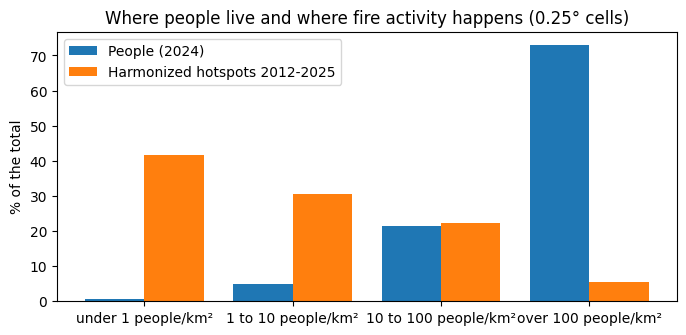

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(labels))
ax.bar(x - 0.2, by_class.share_people_pct, 0.4, label="People (2024)")
ax.bar(x + 0.2, by_class.share_hotspots_pct, 0.4, label="Harmonized hotspots 2012-2025")
ax.set_xticks(x, [f"{l} people/km²" for l in labels])
ax.set_ylabel("% of the total")
ax.set_title("Where people live and where fire activity happens (0.25° cells)")
ax.legend()
fig.savefig(FIG / "07-population-density-classes.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Two cases (7.6)

People living in the 0.25° cells with fire on the peak day(s).

- Valparaíso: `burn_date` 2024-02-02 and 2024-02-03, box west -71.70, south -33.25, east -71.30, north -32.95.
- Ñuble, Biobío and La Araucanía: `burn_date` 2023-02-03.

A cell counts when it has harmonized hotspots that day and intersects the box (Valparaíso) or
belongs to one of the three regions.

In [7]:
VALPO_BOX = dict(west=-71.70, south=-33.25, east=-71.30, north=-32.95)
REGIONS_2023 = "Ñuble|B[ií]o|Araucan"

case_cells = con.execute(f'''
    WITH c AS (SELECT * FROM read_parquet('{(HARM / "cells_daily.parquet").as_posix()}'))
    SELECT 'Valparaíso 2024' AS case_name, cell_lat, cell_lon, sum(hotspots_harmonized) AS hotspots
    FROM c WHERE burn_date IN ('2024-02-02', '2024-02-03')
      AND cell_lat + {CELL} > {VALPO_BOX['south']} AND cell_lat < {VALPO_BOX['north']}
      AND cell_lon + {CELL} > {VALPO_BOX['west']} AND cell_lon < {VALPO_BOX['east']}
    GROUP BY ALL
    UNION ALL
    SELECT 'Ñuble, Biobío, La Araucanía 2023', cell_lat, cell_lon, sum(hotspots_harmonized)
    FROM c WHERE burn_date = '2023-02-03' AND regexp_matches(admin1, '{REGIONS_2023}')
    GROUP BY ALL
''').df()
case_cells = case_cells[case_cells.hotspots > 0].merge(cells_out, on=["cell_lat", "cell_lon"], how="left")
case_cells["population_2024"] = case_cells.population_2024.fillna(0)
cases = case_cells.groupby("case_name", sort=False).agg(
    cells_with_fire=("hotspots", "size"), hotspots=("hotspots", "sum"), people_in_those_cells=("population_2024", "sum"))
cases["people_per_hotspot"] = (cases.people_in_those_cells / cases.hotspots).round(0)
cases[["hotspots", "people_in_those_cells"]] = cases[["hotspots", "people_in_those_cells"]].round()
cases

,cells_with_fire,hotspots,people_in_those_cells,people_per_hotspot
case_name,,,,
Valparaíso 2024,3,403.0,1009728.0,2506.0
"Ñuble, Biobío, La Araucanía 2023",56,8039.0,1915438.0,238.0


In [8]:
v, n = cases.iloc[0], cases.iloc[1]
print(f"Hotspots: the 2023 day had {n.hotspots / v.hotspots:.1f} times the hotspots of Valparaíso's two days.")
print(f"People in the cells with fire: Valparaíso had {v.people_in_those_cells / n.people_in_those_cells:.1f} times "
      f"the people of the 2023 day.")
print(f"People per hotspot: {v.people_per_hotspot:,.0f} (Valparaíso) against {n.people_per_hotspot:,.0f} (2023).")

Hotspots: the 2023 day had 19.9 times the hotspots of Valparaíso's two days.
People in the cells with fire: Valparaíso had 0.5 times the people of the 2023 day.
People per hotspot: 2,506 (Valparaíso) against 238 (2023).


## 5. People within 1, 5 and 10 km of the hotspots of the two cases (7.4)

Finer than step 4: instead of whole 25 km cells, count the WorldPop pixels (about 100 m) whose centre
is within 1, 5 or 10 km of at least one hotspot of the case. Distances in metres in UTM zone 19S
(EPSG:32719), which covers both cases. Hotspots: every satellite, quality filter of block 1
(`hotspots_kept.parquet`), same days and areas as step 4.

In [9]:
from pyproj import Transformer
from scipy.spatial import cKDTree

to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32719", always_xy=True)
RINGS_KM = [1, 5, 10]

pts = con.execute(f'''
    WITH h AS (SELECT * FROM read_parquet('{(HARM / "hotspots_kept.parquet").as_posix()}'))
    SELECT 'Valparaíso 2024' AS case_name, latitude, longitude FROM h
    WHERE burn_date IN ('2024-02-02', '2024-02-03')
      AND latitude BETWEEN {VALPO_BOX['south']} AND {VALPO_BOX['north']}
      AND longitude BETWEEN {VALPO_BOX['west']} AND {VALPO_BOX['east']}
    UNION ALL
    SELECT 'Ñuble, Biobío, La Araucanía 2023', latitude, longitude FROM h
    WHERE burn_date = '2023-02-03' AND regexp_matches(admin1, '{REGIONS_2023}')
''').df()

def people_within(points, raster_path, rings_km):
    pad = max(rings_km) / 80  # degrees; generous margin for 10 km
    west, east = points.longitude.min() - pad, points.longitude.max() + pad
    south, north = points.latitude.min() - pad, points.latitude.max() + pad
    with rasterio.open(raster_path) as r:
        win = rasterio.windows.from_bounds(west, south, east, north, r.transform).round_offsets().round_lengths()
        a = r.read(1, window=win, boundless=True, fill_value=0).astype("float64")
        a[(a == r.nodata) | (a < 0) | ~np.isfinite(a)] = 0
        t = r.window_transform(win)
    rows, cols = np.nonzero(a)
    xs, ys = rasterio.transform.xy(t, rows, cols)
    px, py = to_utm.transform(np.asarray(xs), np.asarray(ys))
    hx, hy = to_utm.transform(points.longitude.to_numpy(), points.latitude.to_numpy())
    dist, _ = cKDTree(np.c_[hx, hy]).query(np.c_[px, py], distance_upper_bound=max(rings_km) * 1000)
    vals = a[rows, cols]
    return {f"within_{k}_km": float(vals[dist <= k * 1000].sum()) for k in rings_km}

rings = []
for case_name, p in pts.groupby("case_name", sort=False):
    row = {"case_name": case_name, "hotspots_raw": len(p)}
    for country, path in RASTERS.items():  # both cases are in Chile; Argentina adds nothing but is checked
        for k, v in people_within(p, path, RINGS_KM).items():
            row[k] = row.get(k, 0.0) + v * SCALE[country]  # same census rescale as step 2
    rings.append(row)
rings = pd.DataFrame(rings).set_index("case_name").round()
rings

,hotspots_raw,within_1_km,within_5_km,within_10_km
case_name,,,,
Valparaíso 2024,1516,203956.0,769563.0,1063455.0
"Ñuble, Biobío, La Araucanía 2023",18443,153077.0,792089.0,1459601.0


## 6. Summary for `docs/findings/07-population.md`

Copy the tables of steps 1 to 5. Decision to record: Chile rescaled to the 2024 census. Limits to keep in the findings, whatever the results: exposure is not
damage; WorldPop models residents (no tourists or seasonal workers); one population year (2024) for
every fire year, and WorldPop starts in 2015; a 0.25° cell is about 25 km wide, so step 4 counts
everyone in the cell and overstates exposure (step 5 is the finer measure).